# 03 — Interpretabilidad del modelo

SHAP (global y local), PDP y LIME sobre el mejor modelo del notebook 02.

In [1]:
import json
from pathlib import Path

import lime.lime_tabular
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import PartialDependenceDisplay

SEED = 42
TARGET = "isFraud"

BASE = Path.cwd()
for candidato in [BASE, *BASE.parents]:
    if (candidato / "modelos" / "modelo_xgb.json").exists():
        RUTA_BASE = candidato
        break
else:
    raise FileNotFoundError("No encontré modelos/modelo_xgb.json. Corre primero el notebook 02.")

RUTA_PROC = RUTA_BASE / "Datos" / "procesado"
RUTA_MODELOS = RUTA_BASE / "modelos"

FEATURES = json.loads((RUTA_PROC / "resumen_preprocesamiento.json").read_text(encoding="utf-8"))["features"]
train = pd.read_parquet(RUTA_PROC / "train.parquet")
prod = pd.read_parquet(RUTA_PROC / "prod.parquet")

booster = xgb.Booster()
booster.load_model(str(RUTA_MODELOS / "modelo_xgb.json"))

def predecir_proba(X):
    return booster.predict(xgb.DMatrix(np.asarray(X), feature_names=FEATURES))

muestra = train.sample(50_000, random_state=SEED)
print(f"Modelo cargado | muestra SHAP: {muestra.shape}")

D:\DSRP-ML3-Proyecto-Final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo cargado | muestra SHAP: (50000, 14)


## SHAP global

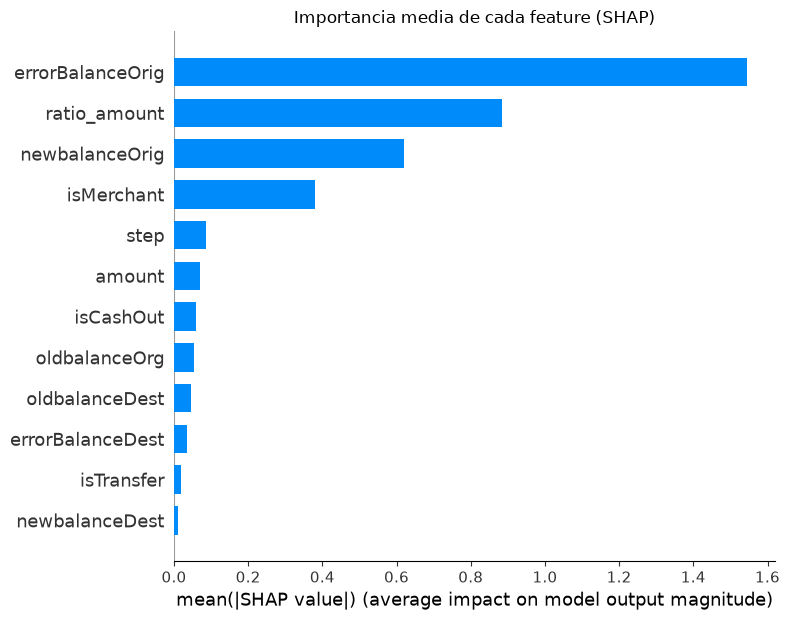

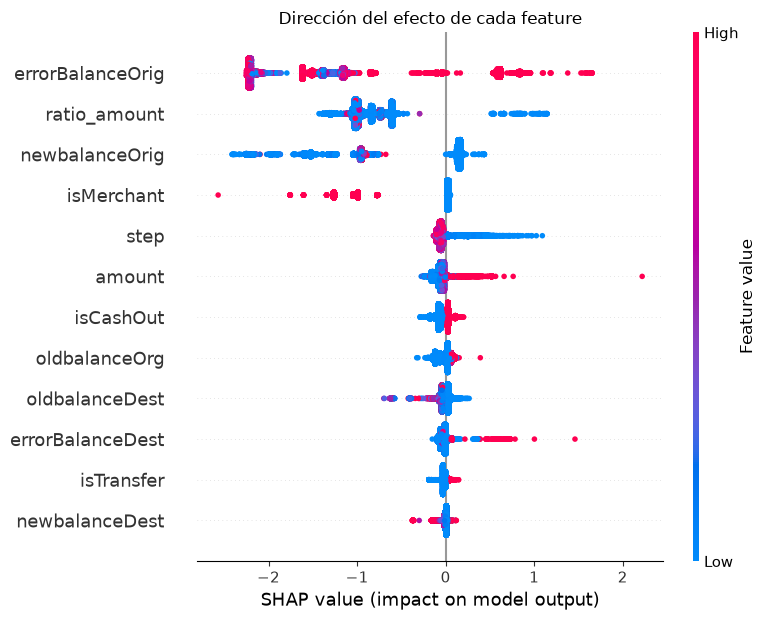

In [2]:
explicador = shap.TreeExplainer(booster)
shap_values = explicador.shap_values(muestra[FEATURES])
if isinstance(shap_values, list):
    shap_values = shap_values[1]

shap.summary_plot(shap_values, muestra[FEATURES], plot_type="bar", show=False)
plt.title("Importancia media de cada feature (SHAP)")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values, muestra[FEATURES], show=False)
plt.title("Dirección del efecto de cada feature")
plt.tight_layout()
plt.show()

## SHAP local: un fraude real y una transacción normal


--- FRAUDE real | probabilidad predicha: 0.9652 ---


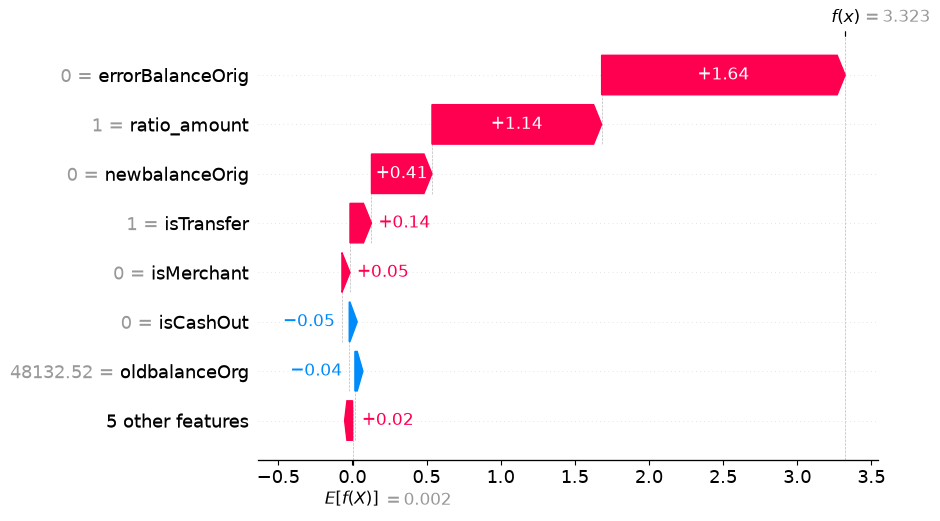


--- transacción normal | probabilidad predicha: 0.0340 ---


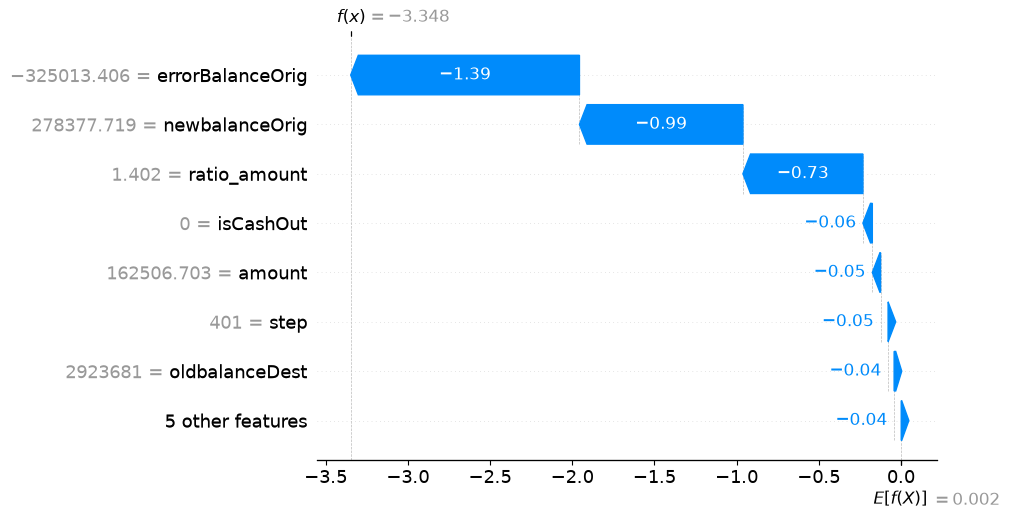

In [3]:
fila_fraude = prod[prod[TARGET] == 1].iloc[100]
fila_normal = prod[prod[TARGET] == 0].iloc[1000]

for etiqueta, fila in [("FRAUDE real", fila_fraude), ("transacción normal", fila_normal)]:
    X_fila = fila[FEATURES].to_frame().T
    sv = explicador.shap_values(X_fila)
    if isinstance(sv, list):
        sv = sv[1]
    print(f"\n--- {etiqueta} | probabilidad predicha: {predecir_proba(X_fila)[0]:.4f} ---")
    shap.plots.waterfall(
        shap.Explanation(
            values=sv[0],
            base_values=float(np.ravel(explicador.expected_value)[0]),
            data=X_fila.values[0],
            feature_names=FEATURES,
        ),
        max_display=8,
    )
    plt.show()

## PDP: efecto parcial de las features más importantes

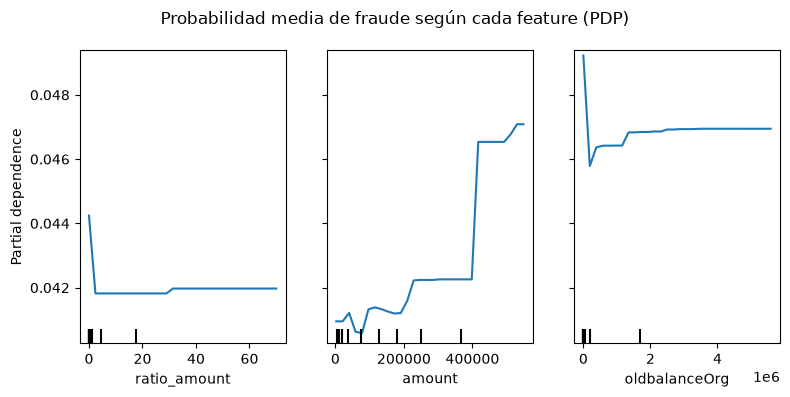

In [4]:
class ModeloFraude(RegressorMixin, BaseEstimator):
    n_features_in_ = len(FEATURES)

    def __init__(self, booster):
        self.booster = booster
        self.booster_ = booster

    def fit(self, X, y):
        return self

    def predict(self, X):
        return self.booster.predict(xgb.DMatrix(np.asarray(X), feature_names=FEATURES))


muestra_pdp = train.sample(10_000, random_state=SEED)
features_pdp = ["ratio_amount", "amount", "oldbalanceOrg"]

fig, ax = plt.subplots(figsize=(8, 4))
PartialDependenceDisplay.from_estimator(
    ModeloFraude(booster),
    muestra_pdp[FEATURES].values,
    features=[FEATURES.index(f) for f in features_pdp],
    feature_names=FEATURES,
    grid_resolution=30,
    ax=ax,
)
plt.suptitle("Probabilidad media de fraude según cada feature (PDP)")
plt.tight_layout()
plt.show()

## LIME: explicación local de una transacción

FRAUDE real | probabilidad predicha: 0.9652


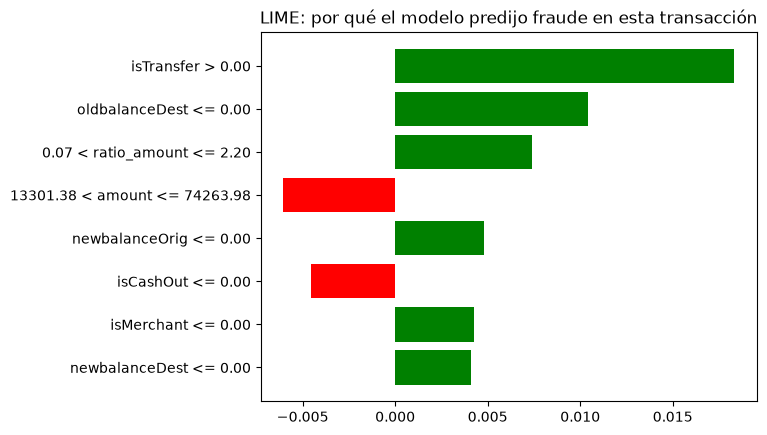

[(0.018, 'isTransfer > 0.00'), (0.01, 'oldbalanceDest <= 0.00'), (0.007, '0.07 < ratio_amount <= 2.20'), (-0.006, '13301.38 < amount <= 74263.98'), (0.005, 'newbalanceOrig <= 0.00'), (-0.005, 'isCashOut <= 0.00'), (0.004, 'isMerchant <= 0.00'), (0.004, 'newbalanceDest <= 0.00')]


In [5]:
def predecir_proba_2d(X):
    p = predecir_proba(X)
    return np.column_stack([1 - p, p])


explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    muestra[FEATURES].values,
    feature_names=FEATURES,
    class_names=["no fraude", "fraude"],
    mode="classification",
    random_state=SEED,
)

X_lime = fila_fraude[FEATURES].to_frame().T
exp = explainer_lime.explain_instance(
    X_lime.values[0], predecir_proba_2d, num_features=8, num_samples=1500
)
print(f"FRAUDE real | probabilidad predicha: {predecir_proba(X_lime)[0]:.4f}")
exp.as_pyplot_figure()
plt.title("LIME: por qué el modelo predijo fraude en esta transacción")
plt.show()
print([(round(v, 3), f) for f, v in exp.as_list()])

## Análisis

- **SHAP global**: `errorBalanceOrig` (1.55) y `ratio_amount` (0.88) dominan con diferencia; después vienen `newbalanceOrig` (0.62) e `isMerchant` (0.38). El orden coincide con la importancia por gain del notebook 02, así que dos métodos distintos dicen lo mismo.
- **SHAP local**: en un fraude real (predicción 0.9652) disparan la predicción `errorBalanceOrig` (+1.64), `ratio_amount` (+1.14) y `newbalanceOrig` (+0.41). En una transacción normal (predicción 0.0340) empujan hacia abajo esas mismas variables: `errorBalanceOrig` (-1.39), `newbalanceOrig` (-0.99), `ratio_amount` (-0.73). Mismo patrón, dirección opuesta.
- **PDP**: las curvas salen casi planas en el rango central: variar `ratio_amount`, `amount` o `oldbalanceOrg` por sí solo casi no mueve la probabilidad promedio; solo montos extremos la suben (~0.15). El modelo decide por combinaciones de variables, no por una sola — por eso el waterfall necesitaba las tres juntas para dispararse.
- **LIME** (otro método, modelo lineal local) en el mismo fraude señala `isTransfer`, saldo destino en 0 y `ratio_amount`. Coincide con SHAP aunque lo calcula de forma totalmente distinta, así que me fío de la explicación.
- Conclusión: lo que detecta el fraude es prácticamente el balance de saldos y el monto contra el saldo; las variables creadas en el notebook 01 son las que sostienen todo.